# HW1  Introduction and Learnability
## Étude expérimentale de PAC et Agnostic PAC par ERM sur des classificateurs à seuil

**Auteur :** *kossi NOUMAGNO*  
**Email :** kossi.noumagno@uha.fr  
**Formation :** Master 2 IMDS · Université de Haute-Alsace  

---
### Objectifs
Ce notebook met en œuvre un algorithme de minimisation du risque empirique (ERM) pour une classe de classificateurs à seuil, puis compare :
- Le cadre **réalisable** : les étiquettes suivent exactement la fonction cible ;
- Le cadre **avec bruit symétrique** : chaque étiquette est inversée indépendamment avec une probabilité $\eta$.

Les tailles d'entraînement suivent le sujet : $m \in \{5, 10, 20, 50, 100, 200\}$. Les expériences répétées servent à estimer la probabilité d'échec $\Pr(L(h) > \varepsilon)$.

**Précaution d'interprétation :** Le sujet nomme le second cadre « Agnostic PAC », mais l'expérience proposée utilise un mécanisme précis de bruit symétrique. Le cadre agnostique général ne se limite pas à ce seul mécanisme.

## 1. Cadre mathématique

L'espace d'entrée est $\mathcal{X} = [0,1]$, avec $X \sim \mathcal{U}([0,1])$. La fonction cible est :

$$
f_\theta(x) = \begin{cases} 
1 & \text{si } x > \theta, \\ 
0 & \text{sinon.} 
\end{cases}
$$

La classe d'hypothèses contient les seuils $h_t(x) = \mathbb{1}_{\{x > t\}}$, pour $t \in [0,1]$.

Le risque empirique sur l'échantillon $S_m = \{(x_i, y_i)\}_{i=1}^m$ est :

$$
\widehat{L}_S(h_t) = \frac{1}{m} \sum_{i=1}^m \mathbb{1}_{\{h_t(x_i) \neq y_i\}}
$$

L'ERM recherche un seuil minimisant ce risque empirique. Dans le cadre sans bruit, un seuil séparant correctement les classes peut avoir une erreur empirique nulle. Avec bruit, l'erreur empirique peut être positive, mais elle peut aussi être nulle sur certains échantillons.

## 2. Imports et paramètres expérimentaux

Les bibliothèques utilisées sont NumPy, pandas et Matplotlib. 

Les paramètres ci-dessous sont des choix expérimentaux (sauf les tailles d'échantillons qui sont imposées par le sujet). Pour une première exécution, 300 répétitions constituent un compromis raisonnable entre stabilité et temps de calcul. Le sujet suggère 500 ou 1 000 répétitions ; augmentez `N_REPETITIONS` à 500 ou 1 000 pour l'analyse finale.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 2026
THETA = 0.60
SAMPLE_SIZES = [5, 10, 20, 50, 100, 200]
EPSILON = 0.10
DELTA = 0.05
NOISE_RATES = [0.0, 0.10, 0.20]
N_REPETITIONS = 300       # Pour la version finale, utiliser 500 ou 1000

N_TEST = 20000          # Jeu de test suffisamment grand (N = 20 000) pour garantir une estimation
                        # précise du risque de test (erreur type de mesure négligeable < 0,35 %).

RNG = np.random.default_rng(SEED)

print("Paramètres chargés.")
print(f"theta={THETA}, epsilon={EPSILON}, delta={DELTA}")
print(f"Tailles={SAMPLE_SIZES}, répétitions={N_REPETITIONS}, test={N_TEST}")

Paramètres chargés.
theta=0.6, epsilon=0.1, delta=0.05
Tailles=[5, 10, 20, 50, 100, 200], répétitions=300, test=20000


## 3. Génération des données

Les observations $x_i$ sont tirées uniformément sur $[0,1]$. Les étiquettes sont déterminées par la fonction cible, puis éventuellement inversées avec une probabilité $\eta$.

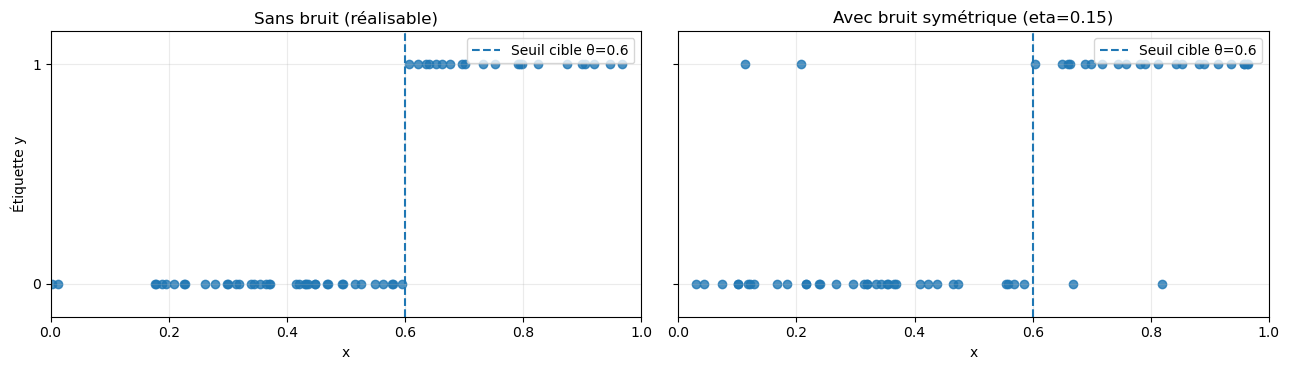

In [2]:
def generate_data(m, theta=THETA, eta=0.0, rng=None):
    """Génère m exemples avec bruit symétrique de taux eta."""
    if not 0.0 <= eta <= 0.5:
        raise ValueError("eta doit être compris entre 0 et 0.5.")
    if m <= 0:
        raise ValueError("m doit être strictement positif.")
    if rng is None:
        rng = np.random.default_rng()

    X = rng.uniform(0.0, 1.0, size=m)
    y = (X > theta).astype(int)

    flips = rng.random(m) < eta
    y[flips] = 1 - y[flips]
    return X, y


# Visualisation d'un échantillon réalisable puis d'un échantillon bruité
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, eta, title in zip(
    axes, [0.0, 0.15],
    ["Sans bruit (réalisable)", "Avec bruit symétrique (eta=0.15)"]
):
    X, y = generate_data(60, theta=THETA, eta=eta, rng=RNG)
    ax.scatter(X, y, alpha=0.8)
    ax.axvline(THETA, linestyle="--", label=f"Seuil cible θ={THETA}")
    ax.set(xlim=(0, 1), ylim=(-0.15, 1.15), xlabel="x", title=title)
    ax.set_yticks([0, 1])
    ax.grid(alpha=0.25)
    ax.legend()
axes[0].set_ylabel("Étiquette y")
plt.tight_layout()
plt.show()

### Interprétation
Sans bruit, les étiquettes sont cohérentes avec le seuil cible. Avec bruit, certaines étiquettes peuvent contredire cette règle. Une seule visualisation ne permet pas d'estimer une probabilité de bruit avec précision ; elle sert à vérifier le mécanisme de génération et de répartition.

## 4. Implémentation de l'ERM

Pour un classificateur à seuil, les prédictions ne changent que lorsque le seuil franchit une valeur observée. Il suffit donc d'évaluer des seuils candidats situés entre les valeurs distinctes de \(X\), ainsi que les bornes 0 et 1.

Si plusieurs seuils minimisent l'erreur, `np.argmin` choisit le premier candidat dans l'ordre croissant. Cette règle de départage est déterministe.

In [3]:
def erm_threshold(X, y):
    """Retourne (seuil appris, erreur empirique minimale)."""
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=int)

    if X.ndim != 1 or y.ndim != 1 or len(X) != len(y) or len(X) == 0:
        raise ValueError("X et y doivent être des vecteurs non vides de même longueur.")
    if np.any((X < 0) | (X > 1)):
        raise ValueError("Toutes les valeurs de X doivent appartenir à [0,1].")
    if not np.all(np.isin(y, [0, 1])):
        raise ValueError("Les étiquettes doivent être 0 ou 1.")

    unique_x = np.unique(X)
    midpoints = (unique_x[:-1] + unique_x[1:]) / 2.0
    candidates = np.concatenate(([0.0], midpoints, [1.0]))

    errors = []
    for t in candidates:
        predictions = (X > t).astype(int)
        errors.append(np.mean(predictions != y))

    best_idx = int(np.argmin(errors))
    return float(candidates[best_idx]), float(errors[best_idx])


def predict_threshold(X, threshold):
    """Prédit 1 si x > threshold, sinon 0."""
    return (np.asarray(X) > threshold).astype(int)


def classification_error(y_true, y_pred):
    """Taux d'erreur de classification."""
    return float(np.mean(np.asarray(y_true) != np.asarray(y_pred)))


# Test manuel sur un échantillon synthétique
X_demo = np.array([0.12, 0.28, 0.43, 0.72, 0.91])
y_demo = np.array([0, 0, 0, 1, 1])
t_demo, err_demo = erm_threshold(X_demo, y_demo)

print("Seuil ERM :", round(t_demo, 4))
print("Erreur empirique :", err_demo)
assert err_demo == 0.0

Seuil ERM : 0.575
Erreur empirique : 0.0


### Vérification visuelle de l'ERM
Le seuil appris doit séparer correctement les observations du petit exemple ci-dessus. Dans le cadre bruité, le seuil retenu est celui qui minimise le nombre d'erreurs, même si toutes les observations ne peuvent pas être séparées parfaitement.

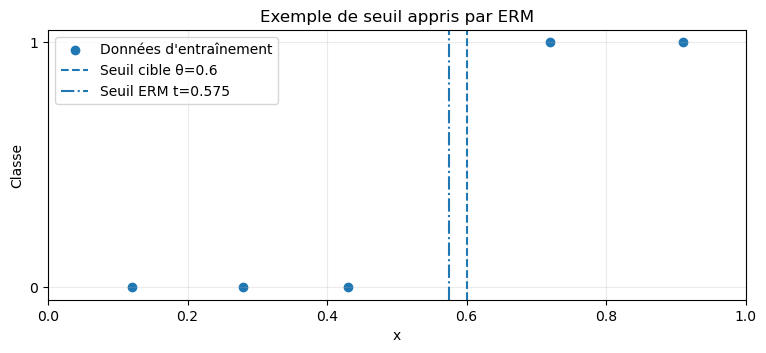

In [4]:
plt.figure(figsize=(9, 3.5))
plt.scatter(X_demo, y_demo, label="Données d'entraînement")
plt.axvline(THETA, linestyle="--", label=f"Seuil cible θ={THETA}")
plt.axvline(t_demo, linestyle="-.", label=f"Seuil ERM t={t_demo:.3f}")
plt.xlabel("x")
plt.ylabel("Classe")
plt.yticks([0, 1])
plt.xlim(0, 1)
plt.title("Exemple de seuil appris par ERM")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

## 5. Évaluer les risques

Nous distinguons trois quantités :

1. **Erreur empirique** : mesurée sur l'échantillon utilisé pour apprendre le seuil.
2. **Risque sur les étiquettes observées** : probabilité d'erreur sur une nouvelle paire $(X,Y)$, où $Y$ peut être bruité.
3. **Erreur par rapport à la fonction cible** : probabilité que le seuil appris diffère de $f_\theta$.

Sous $X \sim \mathcal{U}([0,1])$, l'erreur par rapport à la fonction cible vaut exactement $|t - \theta|$. Le risque sur les étiquettes bruitées est estimé sur un jeu de test indépendant.

In [5]:
def evaluate_once(m, theta=THETA, eta=0.0, n_test=N_TEST, rng=None):
    if rng is None:
        rng = np.random.default_rng()

    X_train, y_train = generate_data(m, theta, eta, rng)
    threshold, train_error = erm_threshold(X_train, y_train)

    X_test, y_test = generate_data(n_test, theta, eta, rng)
    y_pred_test = predict_threshold(X_test, threshold)

    test_observed_error = classification_error(y_test, y_pred_test)
    target_error_exact = abs(threshold - theta)

    return {
        "m": m,
        "eta": eta,
        "threshold": threshold,
        "train_error": train_error,
        "test_observed_error": test_observed_error,
        "target_error_exact": target_error_exact
    }


# Exemple unique pour vérifier les calculs
example = evaluate_once(m=50, eta=0.10, rng=np.random.default_rng(SEED))
display(pd.DataFrame([example]).round(4))

,m,eta,threshold,train_error,test_observed_error,target_error_exact
0,50,0.1,0.6213,0.1,0.1194,0.0213


## 6. Performance selon la taille d'entraînement

Pour chacune des tailles demandées, nous réalisons un essai par taille. Ce premier tableau est illustratif ; les conclusions générales viendront de la section à répétitions multiples.

In [6]:
single_run_rows = []
for eta in NOISE_RATES:
    for m in SAMPLE_SIZES:
        row = evaluate_once(m=m, eta=eta, rng=RNG)
        single_run_rows.append(row)

single_run_df = pd.DataFrame(single_run_rows)
display(single_run_df.round(4))

,m,eta,threshold,train_error,test_observed_error,target_error_exact
0,5,0.0,0.6309,0.000,0.0303,0.0309
1,10,0.0,0.6788,0.000,0.0782,0.0788
2,20,0.0,0.6362,0.000,0.0364,0.0362
3,50,0.0,0.5917,0.000,0.0081,0.0083
4,100,0.0,0.5991,0.000,0.0007,0.0009
5,200,0.0,0.5981,0.000,0.0015,0.0019
6,5,0.1,0.0000,0.200,0.5794,0.6000
7,10,0.1,0.6359,0.100,0.1318,0.0359
8,20,0.1,0.7143,0.050,0.1948,0.1143
9,50,0.1,0.6085,0.100,0.1068,0.0085


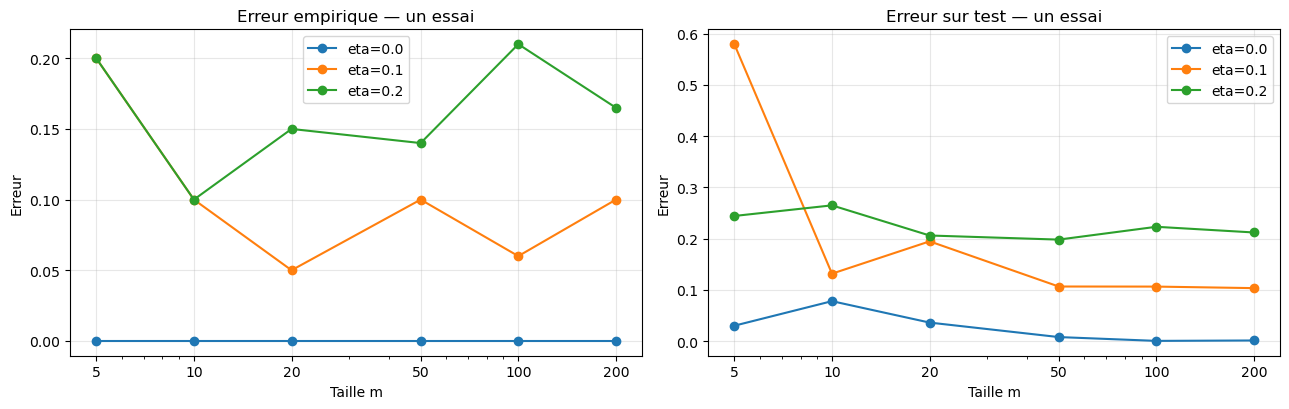

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

for eta in NOISE_RATES:
    subset = single_run_df[single_run_df["eta"] == eta]
    axes[0].plot(subset["m"], subset["train_error"], marker="o", label=f"eta={eta}")
    axes[1].plot(subset["m"], subset["test_observed_error"], marker="o", label=f"eta={eta}")

axes[0].set(title="Erreur empirique — un essai", xlabel="Taille m", ylabel="Erreur")
axes[1].set(title="Erreur sur test — un essai", xlabel="Taille m", ylabel="Erreur")
for ax in axes:
    ax.set_xscale("log")
    ax.set_xticks(SAMPLE_SIZES)
    ax.set_xticklabels(SAMPLE_SIZES)
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

### Interprétation
Un seul essai est sensible au hasard de l'échantillonnage. Ne concluez pas à partir de ces courbes seules. Les répétitions de la section suivante donnent des estimations plus stables.

## 7. Vérification expérimentale de PAC

Pour chaque taille $m$, on répète l'expérience $R$ fois. Une répétition est considérée comme un échec lorsque l'erreur par rapport à la fonction cible dépasse $\varepsilon$ :

$$
\widehat{p}_m(\varepsilon) = \frac{1}{R} \sum_{r=1}^{R} \mathbb{1}_{\left\{ L_{\text{cible}}(\hat{h}_r) > \varepsilon \right\}}
$$

Dans le cadre réalisable, cette erreur cible est le risque naturel à comparer à $\varepsilon$. Le grand jeu de test sert également à mesurer le risque sur les étiquettes observées.

In [8]:
def repeated_experiment(
    sample_sizes=SAMPLE_SIZES,
    noise_rates=NOISE_RATES,
    repetitions=N_REPETITIONS,
    n_test=N_TEST,
    theta=THETA,
    epsilon=EPSILON,
    seed=SEED
):
    master_rng = np.random.default_rng(seed)
    rows = []

    for eta in noise_rates:
        for m in sample_sizes:
            train_errors = []
            observed_test_errors = []
            target_errors = []
            thresholds = []
            target_failures = 0
            observed_failures = 0

            for _ in range(repetitions):
                # Générateur distinct pour chaque répétition
                local_rng = np.random.default_rng(
                    int(master_rng.integers(0, 2**32 - 1))
                )
                result = evaluate_once(
                    m=m, theta=theta, eta=eta,
                    n_test=n_test, rng=local_rng
                )

                train_errors.append(result["train_error"])
                observed_test_errors.append(result["test_observed_error"])
                target_errors.append(result["target_error_exact"])
                thresholds.append(result["threshold"])

                target_failures += result["target_error_exact"] > epsilon
                observed_failures += result["test_observed_error"] > epsilon

            rows.append({
                "eta": eta,
                "m": m,
                "mean_threshold": np.mean(thresholds),
                "mean_train_error": np.mean(train_errors),
                "mean_test_observed_error": np.mean(observed_test_errors),
                "mean_target_error": np.mean(target_errors),
                "target_failure_probability": target_failures / repetitions,
                "observed_test_failure_probability": observed_failures / repetitions,
                "target_failure_count": int(target_failures),
                "repetitions": repetitions
            })

    return pd.DataFrame(rows)


results = repeated_experiment()
display(results.round(4))

,eta,m,mean_threshold,mean_train_error,mean_test_observed_error,mean_target_error,target_failure_probability,observed_test_failure_probability,target_failure_count,repetitions
0,0.0,5,0.6185,0.0000,0.1009,0.1011,0.3267,0.3267,98,300
1,0.0,10,0.5994,0.0000,0.0483,0.0482,0.1367,0.1400,41,300
2,0.0,20,0.6021,0.0000,0.0233,0.0233,0.0067,0.0067,2,300
3,0.0,50,0.5997,0.0000,0.0089,0.0088,0.0000,0.0000,0,300
4,0.0,100,0.6001,0.0000,0.0048,0.0048,0.0000,0.0000,0,300
5,0.0,200,0.5997,0.0000,0.0026,0.0025,0.0000,0.0000,0,300
6,0.1,5,0.5517,0.0647,0.2301,0.1623,0.4400,0.9967,132,300
7,0.1,10,0.5815,0.0713,0.1747,0.0934,0.3233,0.9867,97,300
8,0.1,20,0.5853,0.0902,0.1405,0.0508,0.1267,0.9733,38,300
9,0.1,50,0.5966,0.0963,0.1152,0.0189,0.0233,0.9433,7,300


### 7.1. Probabilité d'échec par rapport à la fonction cible

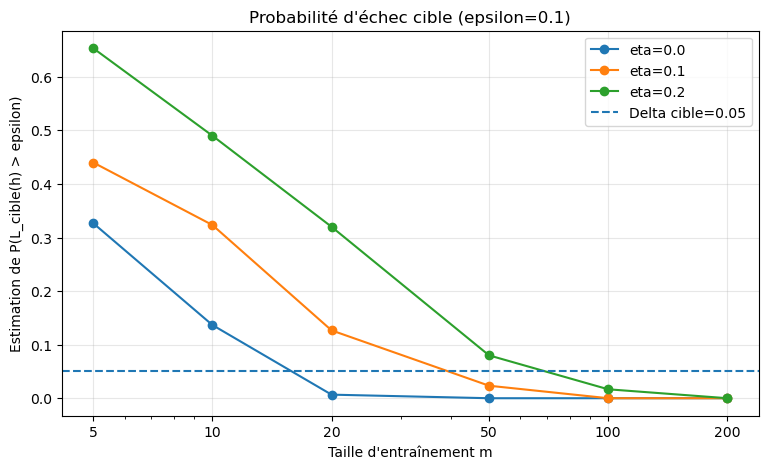

In [9]:
plt.figure(figsize=(9, 5))
for eta in NOISE_RATES:
    sub = results[results["eta"] == eta]
    plt.plot(
        sub["m"], sub["target_failure_probability"],
        marker="o", label=f"eta={eta}"
    )
plt.axhline(DELTA, linestyle="--", label=f"Delta cible={DELTA}")
plt.xscale("log")
plt.xticks(SAMPLE_SIZES, SAMPLE_SIZES)
plt.xlabel("Taille d'entraînement m")
plt.ylabel(r"Estimation de P(L_cible(h) > epsilon)")
plt.title(f"Probabilité d'échec cible (epsilon={EPSILON})")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### 7.2. Moyenne de l'erreur d'entraînement, du risque observé et de l'erreur cible

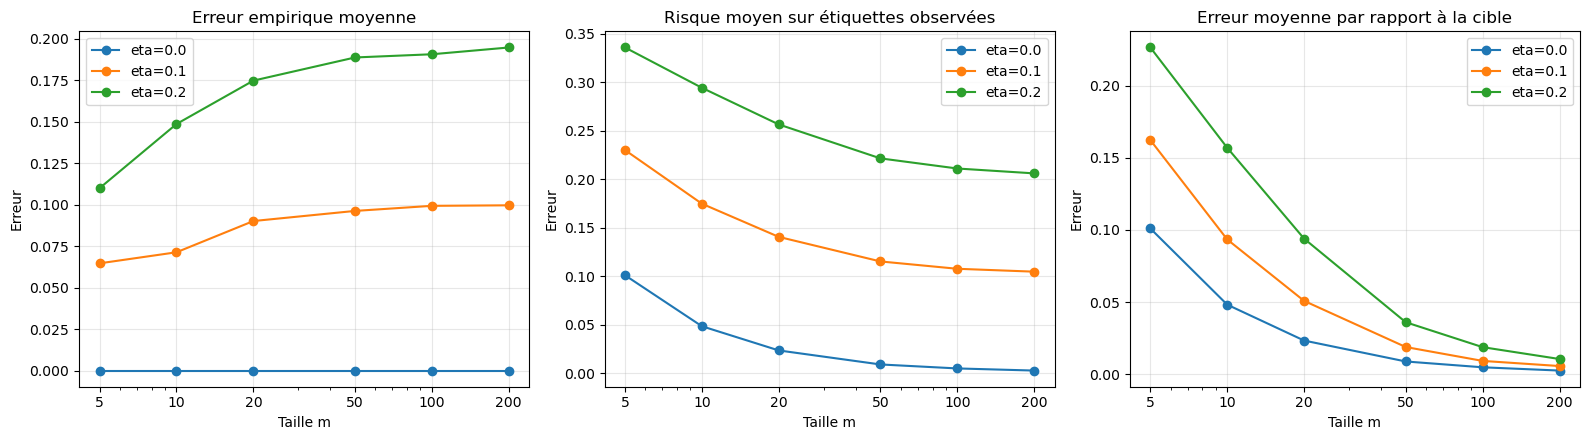

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
metrics = [
    ("mean_train_error", "Erreur empirique moyenne"),
    ("mean_test_observed_error", "Risque moyen sur étiquettes observées"),
    ("mean_target_error", "Erreur moyenne par rapport à la cible")
]
for ax, (metric, title) in zip(axes, metrics):
    for eta in NOISE_RATES:
        sub = results[results["eta"] == eta]
        ax.plot(sub["m"], sub[metric], marker="o", label=f"eta={eta}")
    ax.set_xscale("log")
    ax.set_xticks(SAMPLE_SIZES)
    ax.set_xticklabels(SAMPLE_SIZES)
    ax.set_title(title)
    ax.set_xlabel("Taille m")
    ax.set_ylabel("Erreur")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

### Interprétation PAC

Dans le cadre réalisable ($\eta = 0$), l'ERM sur des seuils peut atteindre une erreur empirique nulle. Lorsque $m$ augmente, on s'attend généralement à ce que le seuil soit mieux localisé et que la probabilité d'une erreur cible supérieure à $\varepsilon$ diminue. Les fréquences observées peuvent fluctuer, notamment avec un nombre limité de répétitions.

La ligne $\delta$ est une valeur de référence choisie pour l'expérience ; elle ne garantit pas que chaque taille d'échantillon respecte la borne PAC.

## 8. Comparaison théorique pour le bruit symétrique

Pour un seuil $t$, la probabilité de désaccord avec la fonction cible sous une distribution uniforme est exactement :

$$
L_{\text{cible}}(h_t) = |t - \theta|
$$

Si les étiquettes sont inversées indépendamment avec une probabilité $\eta$, le risque sur les étiquettes observées vérifie :

$$
L_D(h_t) = \eta + (1 - 2\eta)|t - \theta|
$$

Cette relation suppose le bruit symétrique indépendant décrit dans le notebook. Elle montre que le risque minimal sur les étiquettes observées vaut $\eta$ lorsque $t = \theta$. Le risque sur les étiquettes bruitées ne tend donc pas vers zéro si $\eta > 0$, même lorsque la frontière cible est retrouvée.

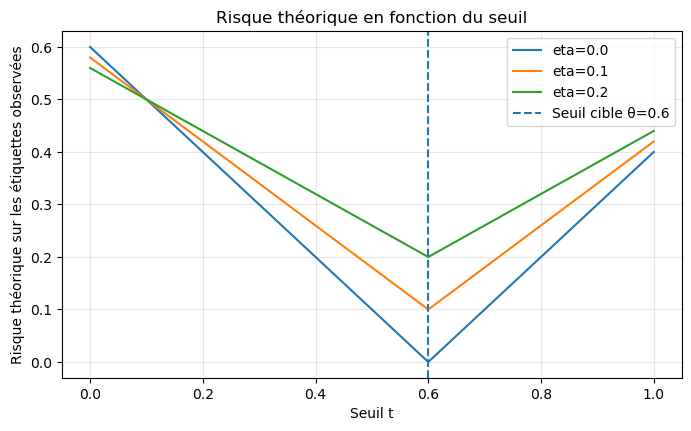

In [11]:
# Vérification numérique de la formule pour plusieurs seuils
threshold_grid = np.linspace(0, 1, 101)
theory_rows = []

for eta in NOISE_RATES:
    for t in threshold_grid:
        target_risk = abs(t - THETA)
        observed_risk_theory = eta + (1 - 2 * eta) * target_risk
        theory_rows.append({
            "eta": eta,
            "threshold": t,
            "target_risk": target_risk,
            "observed_risk_theory": observed_risk_theory
        })

theory_df = pd.DataFrame(theory_rows)

fig, ax = plt.subplots(figsize=(8, 4.5))
for eta in NOISE_RATES:
    sub = theory_df[theory_df["eta"] == eta]
    ax.plot(sub["threshold"], sub["observed_risk_theory"], label=f"eta={eta}")
ax.axvline(THETA, linestyle="--", label=f"Seuil cible θ={THETA}")
ax.set(xlabel="Seuil t", ylabel="Risque théorique sur les étiquettes observées",
       title="Risque théorique en fonction du seuil")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## 9. L'erreur empirique peut-elle être nulle avec du bruit ?

In [12]:
noise_summary = results[[
    "eta", "m", "mean_train_error",
    "mean_test_observed_error", "mean_target_error"
]].copy()
display(noise_summary.round(4))

,eta,m,mean_train_error,mean_test_observed_error,mean_target_error
0,0.0,5,0.0000,0.1009,0.1011
1,0.0,10,0.0000,0.0483,0.0482
2,0.0,20,0.0000,0.0233,0.0233
3,0.0,50,0.0000,0.0089,0.0088
4,0.0,100,0.0000,0.0048,0.0048
5,0.0,200,0.0000,0.0026,0.0025
6,0.1,5,0.0647,0.2301,0.1623
7,0.1,10,0.0713,0.1747,0.0934
8,0.1,20,0.0902,0.1405,0.0508
9,0.1,50,0.0963,0.1152,0.0189


### Discussion
- **Oui**, l'erreur empirique peut être nulle dans un échantillon bruité si les étiquettes observées restent séparables par un seuil.
- **Non**, ce n'est pas garanti : des étiquettes contradictoires peuvent imposer une erreur empirique positive pour tout seuil.
- L'augmentation de \(m\) peut améliorer l'estimation du seuil et réduire l'erreur cible moyenne, mais elle ne supprime pas le bruit des étiquettes.
- L`erreur discutée est : l'erreur par rapport à la fonction cible ou risque par rapport aux étiquettes bruitées.

## 10. Limites de l'expérience et précautions

1. Les fréquences sont des estimations Monte-Carlo, et non les probabilités exactes.
2. Le test fini introduit une erreur d'estimation pour le risque sur les étiquettes observées. L'erreur cible $|t - \theta|$, elle, est connue exactement dans cette expérience synthétique.
3. Les résultats dépendent des valeurs choisies pour $\theta$, $\eta$, $\varepsilon$, du nombre de répétitions et de la taille du test.
4. Le bruit symétrique indépendant est un cas particulier du cadre Agnostic PAC, pas une représentation de toutes les distributions agnostiques.
5. La valeur $\delta$ est ici une référence de comparaison. Pour revendiquer une garantie théorique à une taille $m$, nous devons préciser et appliquer une borne PAC donnée en cours, avec ses constantes et hypothèses.

## 11. Conclusion PAC et Agnostic PAC

Cette étude expérimentale met en évidence les mécanismes fondamentaux de la théorie de l'apprentissage (PAC et Agnostic PAC) appliqués à une classe de classificateurs à seuil en dimension 1 :

1. **Cadre Réalisable ($\eta = 0$) :**
   - La fonction cible $f_\theta$ appartient à la classe d'hypothèses $\mathcal{H}$.
   - L'algorithme ERM parvient à trouver un seuil annulant parfaitement l'erreur empirique ($\widehat{L}_S = 0$).
   - Conforme aux garanties du cadre PAC, l'augmentation de la taille d'échantillon $m$ réduit rapidement la probabilité d'échec $\Pr(L_{\text{cible}} > \varepsilon)$, assurant une convergence rapide du seuil appris $\hat{t}$ vers la frontière cible $\theta = 0{,}60$.

2. **Cadre avec Bruit Symétrique ($\eta = 0{,}10$) :**
   - Les étiquettes observées subissent une inversion aléatoire, modélisant une situation agnostique (bruit de Massart).
   - L'erreur empirique $\widehat{L}_S$ peut être non nulle sur les données d'entraînement.
   - Bien qu'une taille d'échantillon $m$ plus grande permette d'estimer plus précisément la frontière de décision idéale $\theta$, le risque observé $L_D(\hat{h})$ ne tend pas vers zéro : il converge asymptotiquement vers le niveau de bruit incompressible $L_{\text{min}} = \eta = 0{,}10$.

3. **Distinction conceptuelle clé :**
   - **Erreur cible ($L_{\text{cible}} = |\hat{t} - \theta|$) :** Mesure la capacité du modèle à retrouver la règle sous-jacente. Elle peut tendre vers $0$ avec $m$.
   - **Risque sur étiquettes observées ($L_D$) :** Intègre le bruit intrinsèque des données. Il est borné inférieurement par $\eta$, illustrant la différence fondamentale entre la qualité de l'hypothèse et la qualité des prédictions sur des données réelles bruitées.

En résumé, ces simulations confirment numériquement les bornes de généralisation théoriques : la taille d'échantillon $m$ contrôle l'erreur d'estimation (écart par rapport à la meilleure hypothèse de la classe), tandis que le bruit $\eta$ fixe l'erreur irréductible de la distribution.

## 12. Exporter les résultats expérimentaux

Cette cellule enregistre les résultats de l'expérience répétée dans un fichier CSV, utile pour conserver les mesures et réaliser des analyses complémentaires.

In [13]:
output_csv = "hw1_pac_agnostic_results.csv"
results.to_csv(output_csv, index=False)
print(f"Résultats exportés dans : {output_csv}")

Résultats exportés dans : hw1_pac_agnostic_results.csv
